In [358]:
import numpy as np
import pandas as pd
import logging

In [359]:
logger=logging.getLogger(__name__)
logger.setLevel(logging.INFO)
handler=logging.FileHandler('../Logs/IBM.log',mode='a')
formatter=logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')
handler.setFormatter(formatter)
logger.addHandler(handler)

In [360]:
data=pd.read_csv('https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv')
logger.info('Data loaded successfully')

In [361]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [362]:
mapping={'Yes':1,'No':0}
mapping_required_features=['Partner','Dependents','PhoneService','PaperlessBilling']
for each in mapping_required_features:
    data[each]=data[each].map(mapping)
logger.info('Mapping of required features completed successfully')

In [363]:
mapping_gender={'Male':1,'Female':0}
data['gender']=data['gender'].map(mapping_gender)
logger.info('Mapping of gender feature completed successfully')

In [364]:
data.sample(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
4697,0129-KPTWJ,1,0,1,0,72,1,No,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,1,Electronic check,94.65,6747.35,No
2009,7639-OPLNG,1,0,1,1,70,1,Yes,DSL,Yes,...,Yes,Yes,Yes,No,Two year,1,Bank transfer (automatic),79.25,5731.85,No


In [365]:
for each in data.columns:
    print(data[each].value_counts())
    print('\n')

customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64


gender
1    3555
0    3488
Name: count, dtype: int64


SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


Partner
0    3641
1    3402
Name: count, dtype: int64


Dependents
0    4933
1    2110
Name: count, dtype: int64


tenure
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: count, Length: 73, dtype: int64


PhoneService
1    6361
0     682
Name: count, dtype: int64


MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64


InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64


OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
N

In [366]:
data.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [367]:
data.duplicated().sum()

np.int64(0)

In [368]:
data['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [369]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   int64  
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   int64  
 4   Dependents        7043 non-null   int64  
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   int64  
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   int64  
 17  Paymen

In [370]:
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
data['TotalCharges'].fillna(data['TotalCharges'].median(), inplace=True)
logger.info('TotalCharges column converted to numeric and missing values filled with median')

C:\Users\Sulav Dhami\AppData\Local\Temp\ipykernel_19912\2231432538.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  data['TotalCharges'].fillna(data['TotalCharges'].median(), inplace=True)


In [371]:
data['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [372]:
x=data.drop(columns=['customerID','Churn','TotalCharges'])
logger.info('Dropped customerID and Churn columns from the dataset for feature matrix')
logger.warning('Dropped TotalCharges column from the dataset for feature matrix due to potential data leakage')

<Axes: xlabel='tenure', ylabel='MonthlyCharges'>

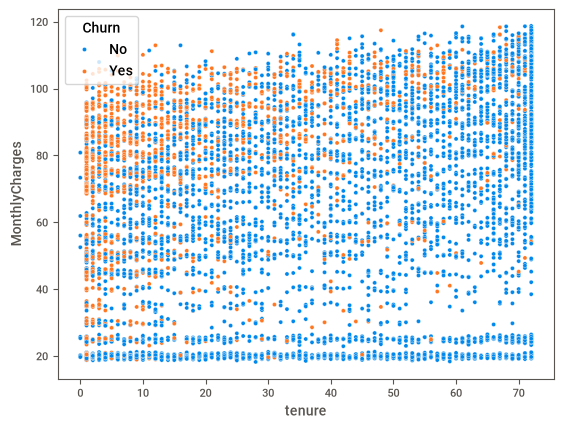

In [373]:
import seaborn as sns
sns.scatterplot(x='tenure',y='MonthlyCharges',hue='Churn',data=data)

<Axes: xlabel='tenure', ylabel='Count'>

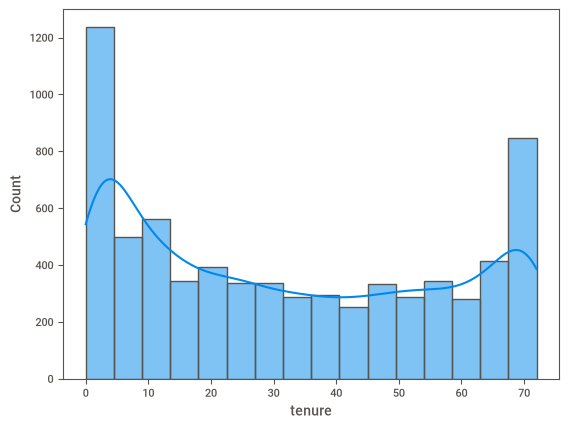

In [374]:
sns.histplot(data,x=data['tenure'],kde=True)

<Axes: xlabel='MonthlyCharges', ylabel='Count'>

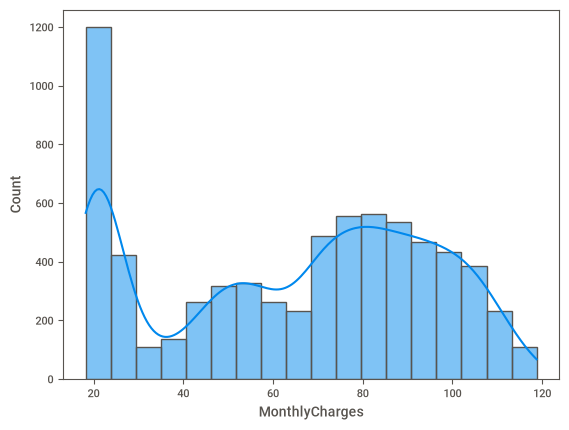

In [375]:
sns.histplot(data,x=data['MonthlyCharges'],kde=True)

In [376]:
from sklearn.model_selection import train_test_split
xTrain,xTest,yTrain,yTest=train_test_split(x,data['Churn'],test_size=0.2,random_state=42)
logger.info('Data split into training and testing sets with test size of 20%')

In [377]:
x.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges'],
      dtype='str')

In [378]:
xTrain=pd.DataFrame(xTrain,columns=x.columns)
xTest=pd.DataFrame(xTest,columns=x.columns)

In [379]:
import sweetviz as sv
report=sv.analyze(data)
report.show_html('EDA.html')
logger.info('Sweetviz report generated and saved as EDA.html')

Feature: gender                              |▉         | [  9%]   00:00 -> (00:00 left)2026-11-27 21:22:46,347 - WARNING - findfont: Failed to find font weight normal for Roboto, now using 500.
2026-11-27 21:22:46,408 - WARNING - findfont: Failed to find font weight normal for Roboto, now using 500.
2026-11-27 21:22:46,554 - WARNING - findfont: Failed to find font weight normal for Roboto, now using 500.
2026-11-27 21:22:46,616 - WARNING - findfont: Failed to find font weight normal for Roboto, now using 500.
Feature: SeniorCitizen                       |█▎        | [ 14%]   00:00 -> (00:02 left)2026-11-27 21:22:46,754 - WARNING - findfont: Failed to find font weight normal for Roboto, now using 500.
2026-11-27 21:22:46,806 - WARNING - findfont: Failed to find font weight normal for Roboto, now using 500.
2026-11-27 21:22:46,910 - WARNING - findfont: Failed to find font weight normal for Roboto, now using 500.
2026-11-27 21:22:46,975 - WARNING - findfont: Failed to find font weight no

Report EDA.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


In [380]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,PowerTransformer,LabelEncoder

ohe_requiring_features=['MultipleLines','InternetService','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','Contract','PaymentMethod']
yj_transform=['tenure','MonthlyCharges']

ct1=ColumnTransformer(
    [
        ('OHE',OneHotEncoder(sparse_output=False,handle_unknown='ignore'),ohe_requiring_features),
        ('YJ',PowerTransformer(method='yeo-johnson'),yj_transform),
    ],
    remainder='passthrough'
)

logger.info('ColumnTransformer created for OneHotEncoding and Yeo-Johnson transformation')

In [381]:
labelEncoder=LabelEncoder()
yTrain=labelEncoder.fit_transform(yTrain)
yTest=labelEncoder.transform(yTest)
logger.info('Label encoding applied to target variable Churn for training and testing sets')

In [382]:
import xgboost as xgb
xgboost_classifier = xgb.XGBClassifier(
    n_estimators=200, 
    learning_rate=0.05, 
    max_depth=5, 
    random_state=42,
    class_weights='balanced',
    use_label_encoder=False,
    eval_metric='logloss'
)

In [383]:
from sklearn.pipeline import Pipeline

XGB=Pipeline(
    [
        ('categorical',ct1),
        ('XGB',xgboost_classifier)
    ]
)

XGB.fit(xTrain,yTrain)
yPred=XGB.predict(xTest)

logger.info('XGBoost model trained and predictions made on test set')

d:\6th sem project\myvenv\Lib\site-packages\xgboost\training.py:200: UserWarning: [21:23:02] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "class_weights", "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [393]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,precision_score,recall_score,roc_curve,roc_auc_score
print('Accuracy: ',accuracy_score(yTest,yPred))
print('Precision: ',precision_score(yTest,yPred))
print('Recall: ',recall_score(yTest,yPred))
logger.info('Model evaluation metrics calculated: Accuracy, Precision, Recall')

Accuracy:  0.8069552874378992
Precision:  0.6644951140065146
Recall:  0.546916890080429


In [385]:
print('Confusion Matrix: \n',confusion_matrix(yTest,yPred))

Confusion Matrix: 
 [[933 103]
 [169 204]]


In [386]:
print('Classification Report: \n',classification_report(yTest,yPred))

Classification Report: 
               precision    recall  f1-score   support

           0       0.85      0.90      0.87      1036
           1       0.66      0.55      0.60       373

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [387]:
import matplotlib.pyplot as plt

2026-11-27 21:23:03,750 - WARNING - findfont: Failed to find font weight normal for Roboto, now using 500.


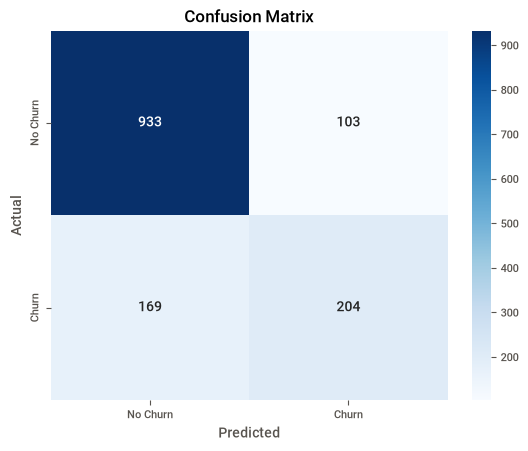

In [388]:
sns.heatmap(confusion_matrix(yTest,yPred),annot=True,fmt='d',cmap='Blues',xticklabels=['No Churn','Churn'],yticklabels=['No Churn','Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
logger.info('Confusion matrix heatmap generated and displayed')

In [389]:
feature_names = XGB.named_steps['categorical'].get_feature_names_out()
importances = XGB.named_steps['XGB'].feature_importances_

In [390]:
feature_importance_df = pd.Series(importances, index=feature_names).sort_values(ascending=False)

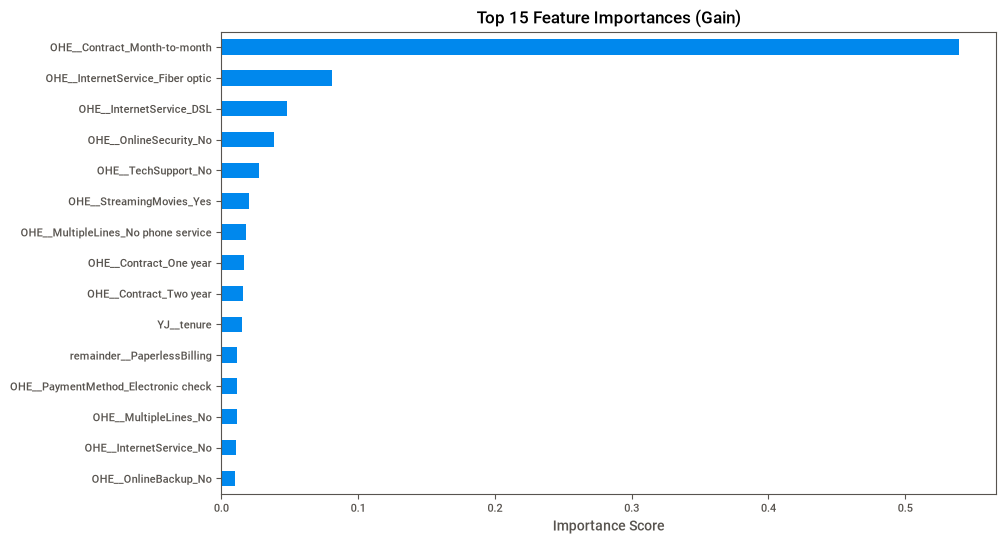

In [391]:
feature_importance_df.head(15).plot(kind='barh', figsize=(10, 6))
plt.title("Top 15 Feature Importances (Gain)")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()
plt.show()
logger.info('Feature importance plot generated and displayed for top 15 features \n')

In [394]:
y_probs=XGB.predict_proba(xTest)[:, 1]
auc_score=roc_auc_score(yTest, y_probs)
print('AUC Score: ', auc_score)

AUC Score:  0.8561167927789911


In [395]:
from sklearn.metrics import average_precision_score

pr_auc = average_precision_score(yTest, y_probs)
print(f"PR-AUC Score: {pr_auc:.4f}")

PR-AUC Score: 0.6945


In [398]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(XGB,xTrain,yTrain,cv=5, scoring="roc_auc")
print(f"Mean CV ROC-AUC: {scores.mean():.4f}")

d:\6th sem project\myvenv\Lib\site-packages\xgboost\training.py:200: UserWarning: [21:33:19] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "class_weights", "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
d:\6th sem project\myvenv\Lib\site-packages\xgboost\training.py:200: UserWarning: [21:33:20] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "class_weights", "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
d:\6th sem project\myvenv\Lib\site-packages\xgboost\training.py:200: UserWarning: [21:33:21] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "class_weights", "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
d:\6th sem project\myvenv\Lib\site-packages\xgboost\training.py:200: UserWarning: [21:33:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: 

Mean CV ROC-AUC: 0.8373


In [399]:
from sklearn.model_selection import GridSearchCV

In [404]:
param_grid = {
    "XGB__n_estimators": [100, 200, 300],
    "XGB__max_depth": [5, 10, None],
    "XGB__learning_rate": [0.01, 0.05, 0.1],
}

grid_search=GridSearchCV(XGB,param_grid,cv=5, scoring="roc_auc", n_jobs=-1, verbose=1)

In [405]:
grid_search.fit(xTrain,yTrain)

Fitting 5 folds for each of 27 candidates, totalling 135 fits


d:\6th sem project\myvenv\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:25:49] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "class_weights", "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'XGB__learning_rate': [0.01, 0.05, ...], 'XGB__max_depth': [5, 10, ...], 'XGB__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_mo

In [406]:
print("Best parameters found: ", grid_search.best_params_)
print("Best CV ROC-AUC Score: {:.4f}".format(grid_search.best_score_))

Best parameters found:  {'XGB__learning_rate': 0.01, 'XGB__max_depth': 5, 'XGB__n_estimators': 300}
Best CV ROC-AUC Score: 0.8423


In [407]:
best_model = grid_search.best_estimator_
y_probs = best_model.predict_proba(xTest)[:, 1]
y_preds = best_model.predict(xTest)

In [410]:
auc_score=roc_auc_score(yTest, y_probs)
print('AUC Score: ', auc_score)

AUC Score:  0.8614929559969773
